# Pipeline de Dados com Pandas e Aprendizagem Supervisionada
## Triagem de risco metabólico associado ao diabetes mellitus tipo 2 utilizando variáveis não invasivas - Subamostra Laboratorial da PNS 2013

**Instituto Federal Farroupilha - Campus São Borja**

---
### Aluno: Lorenzo de Ávila Carpes - 2023002654

> **Escopo deste notebook (Parte 1):** carregamento, análise inicial, limpeza/tratamento e análise
> exploratória (EDA). A separação treino/teste, o treinamento do modelo *baseline* (Regressão
> Logística) e a avaliação são desenvolvidos na Parte 2, estendendo este mesmo notebook.

## 3. Descrição do problema

O Diabetes Mellitus tipo 2 (DM2) é uma condição crônica de progressão silenciosa e alta
subnotificação diagnóstica no Brasil: triangulações sobre a PNS 2013 apontam que cerca de **1/4 a
quase metade** dos indivíduos com hiperglicemia clinicamente significativa desconhecem a própria
condição. Esse *gap* entre o diagnóstico autorreferido e a medição laboratorial objetiva é o
problema central que motiva este trabalho.

**Tarefa de aprendizagem supervisionada:** classificação **binária**. Dado um conjunto de
variáveis **não invasivas** (sociodemográficas, antropométricas e clínicas de aferição simples),
estimar se o indivíduo apresenta **hiperglicemia crônica clinicamente significativa**.

**Variável-alvo (ground truth):** Hemoglobina Glicada (HbA1c), variável `Z034` da subamostra
laboratorial, binarizada pelo critério da *American Diabetes Association*:

$$\text{target} = \begin{cases} 1 & \text{se HbA1c} \geq 6{,}5\% \\ 0 & \text{caso contrário} \end{cases}$$

O uso da HbA1c laboratorial como alvo, em vez do diagnóstico autorreferido, é a decisão que
garante validação clínica objetiva e permite ao modelo enxergar casos não diagnosticados.

**Restrição de projeto:** nenhuma variável laboratorial entra como preditora. O modelo simula uma
ferramenta de triagem rápida da Atenção Primária, operando apenas sobre dados obteníveis sem exame
de sangue.

## 4. Descrição da base de dados

**Fonte:** Pesquisa Nacional de Saúde (PNS) 2013 - Subamostra Laboratorial, IBGE/Ministério da
Saúde. Microdados públicos e anonimizados.

A PNS 2013 é um inquérito domiciliar de abrangência nacional com plano amostral complexo
(conglomerado em três estágios, com estratificação). A **Subamostra Laboratorial** coletou exames
de sangue/urina, incluindo HbA1c, de **8.952 adultos**, viabilizando um desfecho clínico objetivo.

Cada linha do arquivo bruto (`EXAMES_PNS_2013_BRUTA.csv`) representa **um indivíduo**, com 509
colunas. Deste total, selecionamos **16 variáveis preditoras** + alvo + peso amostral, organizadas
em cinco blocos temáticos, conforme a metodologia do TCC:

| Bloco | Variáveis (código PNS) |
|---|---|
| Antropométrico/biológico | `C008` idade, `Z001` sexo, `z004` peso, `z005` altura, `W00303` circ. cintura |
| Pressão arterial | `W00407` sistólica, `W00408` diastólica, `Q002` HAS autorrelato |
| Diagnóstico prévio | `Q060` colesterol alto |
| Sociodemográfico | `Z003` raça/cor, `VDD004` escolaridade, `I001` plano de saúde, `regiao` |
| Autopercepção | `N001` saúde autoavaliada |
| **Alvo** | `Z034` HbA1c |
| **Ponderação** | `peso_lab` peso amostral laboratorial (IBGE, Nota Técnica 2020) |

> **Nota sobre o peso amostral (`peso_lab`):** por causa do desenho complexo e da não resposta na
> coleta biológica, o IBGE recalibrou o peso laboratorial. Ele é usado na EDA para produzir
> estimativas representativas da população adulta brasileira (e **não** a distribuição bruta da
> amostra). Na modelagem, o desbalanceamento é tratado por aprendizagem sensível ao custo
> (`class_weight='balanced'`), preservando a estrutura amostral, decisão detalhada na Parte 2.

## 5. Importação das bibliotecas

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from google.colab import drive
drive.mount('/content/drive')

# Paleta "Clinical Teal" (consistente com a identidade visual do projeto)
TEAL      = "#0F766E"
TEAL_SOFT = "#5EEAD4"
CORAL     = "#E76F51"   # destaque para a classe de risco
INK       = "#1F2937"
GRID      = "#E5E7EB"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.edgecolor": INK,
    "axes.titleweight": "bold", "axes.grid": True, "grid.color": GRID,
    "axes.axisbelow": True, "figure.autolayout": True,
})
pd.set_option("display.max_columns", 60)
print("Bibliotecas carregadas.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Bibliotecas carregadas.


## 6. Carregamento dos dados

**Observação nº 1 da PNS - separador decimal.** Nos microdados, valores numéricos são gravados com
**vírgula decimal** (`'38,00'`, `'5,50'`, `'0,58'`). Ler ingenuamente faria o Pandas interpretar
tudo como texto e quebrar o pipeline de forma silenciosa. Por isso é realizada a leitura das colunas de interesse
como *string* e convertemos o tipo de forma explícita e auditável na etapa de limpeza.

In [7]:
PATH_CSV = '/content/drive/MyDrive/PNS_Banco de dados/EXAMES_PNS_2013_BRUTA.csv'  # ajuste o caminho se necessário

# Dicionário de-para: código oficial PNS -> nome legível (rastreabilidade com o TCC)
DE_PARA = {
    "C008": "idade",      "Z001": "sexo",          "Z003": "raca_cor",
    "z004": "peso_kg",    "z005": "altura_cm",     "W00303": "circ_cintura",
    "W00407": "pas",      "W00408": "pad",         "Q002": "has_autorrelato",
    "Q060": "colesterol_alto", "N001": "saude_autoaval", "VDD004": "escolaridade",
    "I001": "plano_saude","regiao": "regiao",      "Z034": "hba1c",
    "peso_lab": "peso_lab",
}
COLS_ORIG = list(DE_PARA.keys())

# Leitura seletiva (16 preditoras + alvo + peso), tudo como string para conversão controlada
df_raw = pd.read_csv(PATH_CSV, usecols=COLS_ORIG, dtype=str, keep_default_na=False)
df_raw = df_raw.rename(columns=DE_PARA)
print(f"Dimensões do recorte bruto: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
df_raw.head()

Dimensões do recorte bruto: 8952 linhas x 16 colunas


,sexo,idade,raca_cor,peso_kg,altura_cm,hba1c,plano_saude,saude_autoaval,has_autorrelato,colesterol_alto,escolaridade,circ_cintura,pas,pad,regiao,peso_lab
0,"1,00","18,00","4,00","49,30","166,80","5,35",2,2,,,2,"67,70","95,00","52,00","1,00","0,46"
1,"1,00","18,00","4,00","66,10","170,00","4,58",2,1,3,2,4,"79,50","121,50","68,50","2,00","1,04"
2,"1,00","18,00","1,00","71,70","176,70","5,44",2,2,3,2,4,"84,50","126,00","76,00","5,00","1,18"
3,"1,00","18,00","4,00","67,40","160,50","5,44",2,2,,,1,"82,10","122,50","72,00","2,00","1,36"
4,"1,00","19,00","4,00","84,20","169,20","5,20",2,2,3,2,4,"100,20","107,40","64,40","1,00","0,51"


## 7. Análise inicial da base

Antes de qualquer limpeza, está sendo realizada a inpeção de: dimensões, tipos, valores ausentes, duplicados e a
natureza de cada variável (categórica / numérica / alvo).

In [8]:
# Grupos conceituais das variáveis (guiam conversão de tipo e tratamento)
CONTINUAS = ["idade", "peso_kg", "altura_cm", "circ_cintura", "pas", "pad"]
CATEGORICAS = ["sexo", "raca_cor", "regiao", "escolaridade", "saude_autoaval",
               "plano_saude", "has_autorrelato", "colesterol_alto"]
ALVO = "hba1c"
PESO = "peso_lab"

print("VARIÁVEIS NUMÉRICAS (contínuas):", CONTINUAS)
print("VARIÁVEIS CATEGÓRICAS          :", CATEGORICAS)
print("COLUNA ALVO                    :", ALVO, "(-> binarizada em HbA1c >= 6,5%)")
print("PESO AMOSTRAL                  :", PESO)

VARIÁVEIS NUMÉRICAS (contínuas): ['idade', 'peso_kg', 'altura_cm', 'circ_cintura', 'pas', 'pad']
VARIÁVEIS CATEGÓRICAS          : ['sexo', 'raca_cor', 'regiao', 'escolaridade', 'saude_autoaval', 'plano_saude', 'has_autorrelato', 'colesterol_alto']
COLUNA ALVO                    : hba1c (-> binarizada em HbA1c >= 6,5%)
PESO AMOSTRAL                  : peso_lab


In [9]:
# Conversão numérica auxiliar: troca vírgula por ponto e vazio por NaN
def to_num(serie):
    return pd.to_numeric(serie.str.replace(",", ".", regex=False).replace("", np.nan),
                         errors="coerce")

# Visão de ausentes e duplicados sobre o recorte bruto (valores '' = não respondido/inadequado)
ausentes = (df_raw.replace("", np.nan).isna().sum()
            .sort_values(ascending=False).rename("qtd_ausente").to_frame())
ausentes["pct"] = (100 * ausentes["qtd_ausente"] / len(df_raw)).round(1)
print("Linhas duplicadas (idênticas):", df_raw.duplicated().sum())
print(f"Total de linhas: {len(df_raw)}\n")
print("Valores ausentes por variável:")
ausentes

Linhas duplicadas (idênticas): 0
Total de linhas: 8952

Valores ausentes por variável:


,qtd_ausente,pct
colesterol_alto,1390,15.5
hba1c,411,4.6
has_autorrelato,282,3.2
peso_kg,97,1.1
pas,97,1.1
circ_cintura,97,1.1
altura_cm,97,1.1
pad,97,1.1
saude_autoaval,8,0.1
regiao,6,0.1


## 8. Limpeza e tratamento dos dados

O tratamento segue uma ordem deliberada para **prevenir vazamento de informação (*data leakage*)**.
Nesta parte foi executada apenas operações *linha a linha* (que não usam estatísticas entre linhas e,
portanto, não vazam):

1. **Padronização decimal e conversão de tipos** (vírgula → ponto).
2. **Decodificação de códigos de ausência** (`Z003 = 9` "Ignorado" → `NaN`; células vazias → `NaN`).
3. **Remoção de duplicados.**
4. **Remoção de linhas** sem alvo válido e sem nenhuma medição antropométrica/pressórica.
5. **Variáveis derivadas limpas** (IMC e Razão Cintura-Estatura), calculadas por indivíduo.
6. **Separação entre preditoras (X) e alvo (y).**

> **Decisão metodológica - imputação diferida.** A auditoria mostrou que *todos* os ausentes das
> variáveis contínuas pertencem ao mesmo bloco de pessoas não medidas (removidas no passo 4). Logo,
> após a limpeza estrutural **não restam ausentes contínuos**, e o buraco real está nas variáveis
> **categóricas** (autorrelatos). A imputação (KNN nas contínuas, como rede de segurança, e moda
> nas categóricas) e as composições que dela dependem (HAS Combinada, Multimorbidade Metabólica)
> são executadas **após a divisão treino/teste**, ajustadas somente no treino, na Parte 2. Fazer
> isso agora, sobre a base inteira, contaminaria o conjunto de teste.

### 8.1 Padronização decimal e conversão de tipos

In [10]:
df = df_raw.copy()

# Contínuas + alvo + peso -> numérico (vírgula tratada)
for c in CONTINUAS + [ALVO, PESO]:
    df[c] = to_num(df[c])

# Categóricas -> inteiro nullable (preserva NaN sem virar float)
for c in CATEGORICAS:
    df[c] = to_num(df[c]).astype("Int64")

print(df.dtypes)

sexo                 Int64
idade              float64
raca_cor             Int64
peso_kg            float64
altura_cm          float64
hba1c              float64
plano_saude          Int64
saude_autoaval       Int64
has_autorrelato      Int64
colesterol_alto      Int64
escolaridade         Int64
circ_cintura       float64
pas                float64
pad                float64
regiao               Int64
peso_lab           float64
dtype: object


### 8.2 Decodificação de códigos de ausência

Em `raca_cor` (`Z003`), o código `9` significa "Ignorado", não é uma categoria válida e deve
virar ausente. As demais ausências já foram capturadas como `NaN` na conversão (células vazias =
"não aplicável" / "amostra inadequada").

In [11]:
antes = (df["raca_cor"] == 9).sum()
df["raca_cor"] = df["raca_cor"].replace(9, np.nan)
print(f"raca_cor == 9 ('Ignorado') convertidos para NaN: {antes}")

raca_cor == 9 ('Ignorado') convertidos para NaN: 2


### 8.3 Remoção de duplicados

In [12]:
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicados removidos: {n0 - len(df)} | Linhas restantes: {len(df)}")

Duplicados removidos: 0 | Linhas restantes: 8952


### 8.4 Remoção de linhas inválidas

Dois critérios de exclusão:
- **Alvo ausente:** sem HbA1c válida não há *ground truth*; imputar o alvo invalidaria o desfecho.
- **Bloco de medição 100% ausente:** indivíduos sem peso, altura, cintura e pressão não têm nenhum
  preditor contínuo, logo não há base para imputação confiável.

In [13]:
MEDICAO = ["peso_kg", "altura_cm", "circ_cintura", "pas", "pad"]

sem_alvo = df[ALVO].isna()
sem_medicao = df[MEDICAO].isna().all(axis=1)

print(f"Base antes das exclusões:       {len(df)}")
print(f"(-) alvo (HbA1c) ausente:       -{sem_alvo.sum()}")
print(f"(-) bloco de medição ausente:   -{(sem_medicao & ~sem_alvo).sum()} (adicionais)")

df = df[~sem_alvo & ~sem_medicao].reset_index(drop=True)
print(f"= Amostra analítica final:      {len(df)}")

# Sanidade: as contínuas realmente ficaram sem ausentes?
print("\nAusentes remanescentes nas contínuas:")
print(df[CONTINUAS].isna().sum().to_string())
print("\nAusentes remanescentes nas categóricas (serão imputados na Parte 2, pós-split):")
print(df[CATEGORICAS].isna().sum().to_string())

Base antes das exclusões:       8952
(-) alvo (HbA1c) ausente:       -411
(-) bloco de medição ausente:   -90 (adicionais)
= Amostra analítica final:      8451

Ausentes remanescentes nas contínuas:
idade           0
peso_kg         0
altura_cm       0
circ_cintura    0
pas             0
pad             0

Ausentes remanescentes nas categóricas (serão imputados na Parte 2, pós-split):
sexo                  0
raca_cor              2
regiao                4
escolaridade          0
saude_autoaval        0
plano_saude           0
has_autorrelato     261
colesterol_alto    1297


### 8.5 Variáveis derivadas (limpas, calculadas por indivíduo)

Cálculos *row-wise*, sem estatística entre linhas, seguros contra *leakage* e por isso feitos aqui.

- **IMC** = peso / altura² (fórmula de Quetelet), preditor basal de adiposidade geral.
- **RCEst** (Razão Cintura-Estatura) = cintura / altura, que contextualiza a adiposidade central
  pelo porte corporal, dimensão não capturada isoladamente pelo IMC.

> As composições **HAS Combinada** e **Multimorbidade Metabólica** dependem de autorrelatos
> (`Q002`, `Q060`) que ainda contêm ausentes, por isso são construídas na Parte 2, após a
> imputação ajustada no treino.

In [14]:
df["imc"]   = df["peso_kg"] / (df["altura_cm"] / 100.0) ** 2
df["rcest"] = df["circ_cintura"] / df["altura_cm"]

print(df[["peso_kg", "altura_cm", "imc", "circ_cintura", "rcest"]].describe().round(2))

       peso_kg  altura_cm      imc  circ_cintura    rcest
count  8451.00    8451.00  8451.00       8451.00  8451.00
mean     70.08     162.18    26.60         91.20     0.56
std      15.20       9.54     5.11         13.14     0.08
min      30.00     131.00    13.11         50.00     0.33
25%      59.30     155.20    22.97         81.50     0.50
50%      68.10     162.00    26.02         90.50     0.56
75%      79.00     168.85    29.47        100.00     0.62
max     179.00     199.30    61.35        149.70     0.95


### 8.6 Binarização do alvo e separação X / y

In [15]:
LIMIAR_HBA1C = 6.5
df["target"] = (df[ALVO] >= LIMIAR_HBA1C).astype(int)

# X = preditoras não invasivas (exclui alvo, HbA1c bruta e peso amostral).
# imc e rcest substituem peso/altura brutos; peso/altura ficam fora do X final.
PREDITORAS = (["idade", "sexo", "imc", "circ_cintura", "rcest", "pas", "pad",
               "has_autorrelato", "colesterol_alto", "raca_cor", "escolaridade",
               "plano_saude", "regiao", "saude_autoaval"])

X = df[PREDITORAS].copy()
y = df["target"].copy()
peso = df[PESO].copy()   # reservado para EDA ponderada e diagnóstico

dist = y.value_counts().sort_index()
print("Distribuição do alvo (contagem bruta):")
print(f"  0 (HbA1c < 6,5%): {dist[0]:5d}  ({100*dist[0]/len(y):.1f}%)")
print(f"  1 (HbA1c >= 6,5%): {dist[1]:5d}  ({100*dist[1]/len(y):.1f}%)")
print(f"\nRazão de desbalanceamento ~ 1:{dist[0]//dist[1]}  ->  justifica class_weight='balanced'")
print(f"X: {X.shape} | y: {y.shape}")

Distribuição do alvo (contagem bruta):
  0 (HbA1c < 6,5%):  7858  (93.0%)
  1 (HbA1c >= 6,5%):   593  (7.0%)

Razão de desbalanceamento ~ 1:13  ->  justifica class_weight='balanced'
X: (8451, 14) | y: (8451,)


## 9. Análise exploratória (EDA)

Três recortes, com **estimativas ponderadas por `peso_lab`** onde faz sentido para refletir a
população adulta brasileira, não apenas a amostra bruta.

### 9.1 Distribuição da HbA1c e o desbalanceamento do alvo

O histograma expõe visualmente por que a **acurácia é uma métrica enganosa** aqui: a classe de
risco é minoritária. Um classificador que sempre responde "sem risco" acertaria a maioria e teria
Recall ~ 0, sendo completamente inútil como triagem.

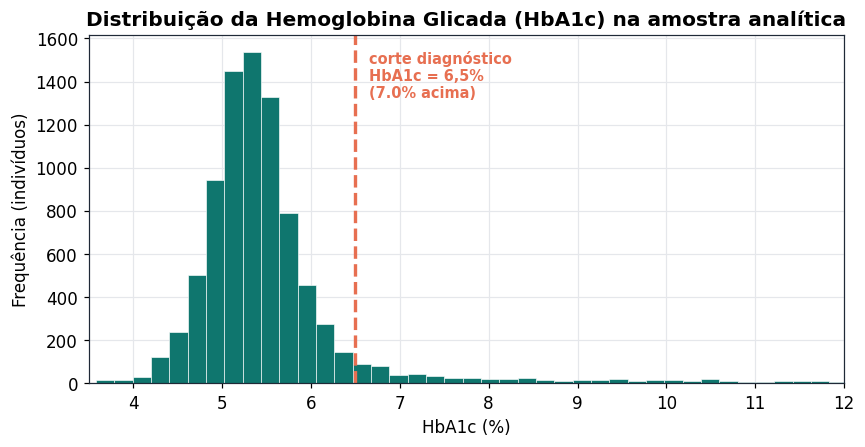

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(df["hba1c"], bins=60, color=TEAL, edgecolor="white", linewidth=0.4)
ax.axvline(LIMIAR_HBA1C, color=CORAL, lw=2.2, ls="--")
pct_pos = 100 * y.mean()
ax.text(LIMIAR_HBA1C + 0.15, ax.get_ylim()[1]*0.82,
        f"corte diagnóstico\nHbA1c = 6,5%\n({pct_pos:.1f}% acima)",
        color=CORAL, fontsize=9.5, fontweight="bold")
ax.set_title("Distribuição da Hemoglobina Glicada (HbA1c) na amostra analítica")
ax.set_xlabel("HbA1c (%)"); ax.set_ylabel("Frequência (indivíduos)")
ax.set_xlim(3.5, 12)
plt.show()

### 9.2 Prevalência ponderada de hiperglicemia por macrorregião

Estimativa ponderada por `peso_lab`, conectando a EDA à evidência do TCC sobre disparidades
regionais (Norte/Nordeste com maior subnotificação).

/tmp/ipykernel_594/1906890383.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  prev = (tmp.groupby("regiao_nome").apply(prev_ponderada)


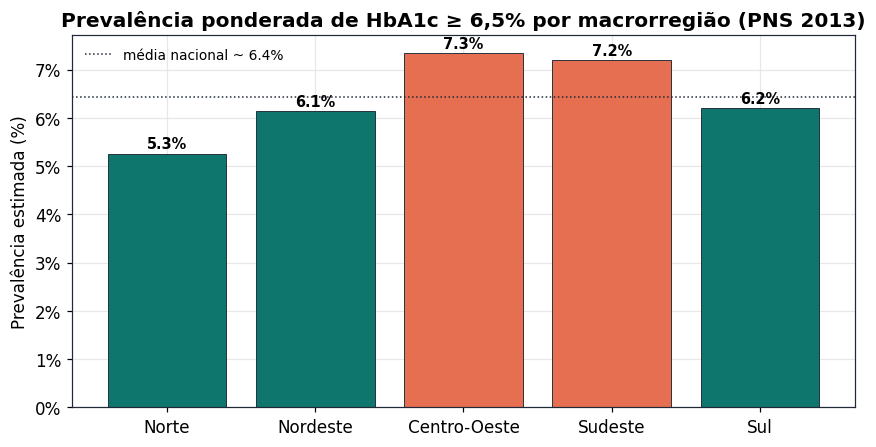

In [17]:
REGIOES = {1: "Norte", 2: "Nordeste", 3: "Sudeste", 4: "Sul", 5: "Centro-Oeste"}

tmp = df.dropna(subset=["regiao"]).copy()
tmp["regiao_nome"] = tmp["regiao"].map(REGIOES)

# Prevalência ponderada = soma(peso*target) / soma(peso) por região
def prev_ponderada(g):
    return 100 * np.average(g["target"], weights=g["peso_lab"])
prev = (tmp.groupby("regiao_nome").apply(prev_ponderada)
        .reindex(["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]))

fig, ax = plt.subplots(figsize=(8, 4.2))
cores = [CORAL if v >= prev.mean() else TEAL for v in prev.values]
bars = ax.bar(prev.index, prev.values, color=cores, edgecolor=INK, linewidth=0.6)
ax.axhline(prev.mean(), color=INK, lw=1, ls=":", label=f"média nacional ~ {prev.mean():.1f}%")
for b, v in zip(bars, prev.values):
    ax.text(b.get_x()+b.get_width()/2, v+0.1, f"{v:.1f}%", ha="center", fontsize=9.5, fontweight="bold")
ax.set_title("Prevalência ponderada de HbA1c ≥ 6,5% por macrorregião (PNS 2013)")
ax.set_ylabel("Prevalência estimada (%)"); ax.legend(frameon=False, fontsize=9)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
plt.show()

### 9.3 Adiposidade central por classe de risco

Boxplot da circunferência da cintura entre as duas classes do alvo. Diferença de mediana sustenta
a hipótese clínica de que a adiposidade central discrimina risco metabólico sendo um sinal útil ao modelo.

/tmp/ipykernel_594/2625825401.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(dados, patch_artist=True, widths=0.55,


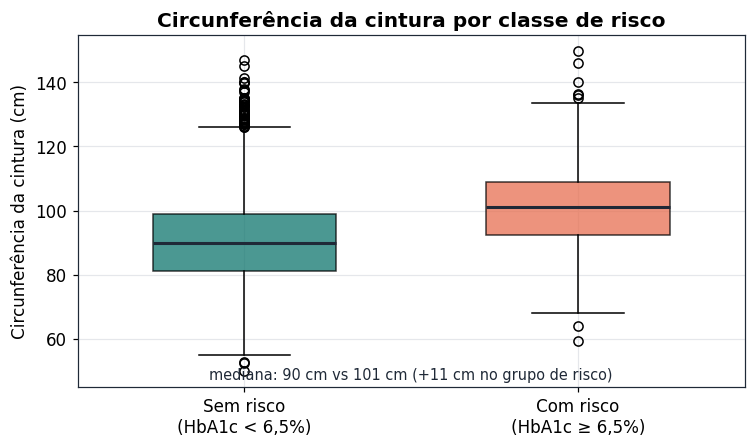

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.2))
dados = [df.loc[y == 0, "circ_cintura"].dropna(),
         df.loc[y == 1, "circ_cintura"].dropna()]
bp = ax.boxplot(dados, patch_artist=True, widths=0.55,
                medianprops=dict(color=INK, lw=2),
                labels=["Sem risco\n(HbA1c < 6,5%)", "Com risco\n(HbA1c ≥ 6,5%)"])
for patch, cor in zip(bp["boxes"], [TEAL, CORAL]):
    patch.set_facecolor(cor); patch.set_alpha(0.75)
ax.set_title("Circunferência da cintura por classe de risco")
ax.set_ylabel("Circunferência da cintura (cm)")
med0, med1 = dados[0].median(), dados[1].median()
ax.text(0.5, 0.02, f"mediana: {med0:.0f} cm vs {med1:.0f} cm (+{med1-med0:.0f} cm no grupo de risco)",
        transform=ax.transAxes, ha="center", fontsize=9.5, color=INK)
plt.show()

### 9.4 Síntese da EDA

- **Desbalanceamento confirmado (~7% positivos):** fundamenta a escolha de Recall como métrica
  prioritária e de `class_weight='balanced'`, em vez de acurácia.
- **Disparidade regional** coerente com a literatura da PNS, reforça a inclusão de `regiao` como
  determinante social.
- **Adiposidade central** separa visivelmente as classes, evidência a favor de cintura/RCEst como
  preditores.

**Próxima etapa (Parte 2):** divisão estratificada 80/20 → imputação ajustada no treino (KNN
contínuo + moda categórica) → construção de HAS Combinada e Multimorbidade → Regressão Logística
(*baseline*) com `class_weight='balanced'` → avaliação por matriz de confusão, Recall, F1 e
AUC-ROC (a acurácia é reportada, mas contextualizada como insuficiente).

---
# Parte 2 - Aprendizagem supervisionada (baseline)

Modelo *baseline*: **Regressão Logística**, escolhida pela transparência paramétrica e consolidação
em estudos epidemiológicos. Todo o tratamento que usa estatística entre linhas (imputação,
codificação, escalonamento) é **ajustado apenas no conjunto de treino** e aplicado ao teste, para
não vazar informação.

## 10. Separação treino/teste

Divisão **80/20 estratificada** pelo alvo, preservando a proporção de ~7% de positivos nos dois
subconjuntos, sendo essencial na base devido ao desbalanceamento.

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print(f"Treino: {X_train.shape[0]} linhas | positivos: {y_train.mean()*100:.1f}%")
print(f"Teste : {X_test.shape[0]} linhas | positivos: {y_test.mean()*100:.1f}%")

Treino: 6760 linhas | positivos: 7.0%
Teste : 1691 linhas | positivos: 7.0%


## 11. Preparação para a modelagem (pós-split, ajustada no treino)

### 11.1 Imputação de ausentes

- **Contínuas** (`idade, imc, circ_cintura, rcest, pas, pad`): `KNNImputer` como rede de segurança.
  Na prática, após a limpeza da Parte 1 não há ausentes contínuos - o imputador não altera nada,
  mas fica documentado no pipeline conforme a metodologia do TCC.
- **Categóricas**: imputação pela **moda** (`most_frequent`), que resolve o buraco real da base
  (autorrelatos, com destaque para colesterol).

O `KNNImputer` e o imputador de moda são **ajustados no treino** (`fit`) e apenas **aplicados**
(`transform`) ao teste.

In [20]:
from sklearn.impute import KNNImputer, SimpleImputer

CONT = ["idade", "imc", "circ_cintura", "rcest", "pas", "pad"]
CATE = ["sexo", "raca_cor", "regiao", "escolaridade", "saude_autoaval",
        "plano_saude", "has_autorrelato", "colesterol_alto"]

knn = KNNImputer(n_neighbors=5, weights="distance")
tr_cont = pd.DataFrame(knn.fit_transform(X_train[CONT]), columns=CONT, index=X_train.index)
te_cont = pd.DataFrame(knn.transform(X_test[CONT]),      columns=CONT, index=X_test.index)

moda = SimpleImputer(strategy="most_frequent")
tr_cat = pd.DataFrame(moda.fit_transform(X_train[CATE].astype(float)), columns=CATE, index=X_train.index)
te_cat = pd.DataFrame(moda.transform(X_test[CATE].astype(float)),      columns=CATE, index=X_test.index)

Xtr = pd.concat([tr_cont, tr_cat], axis=1)
Xte = pd.concat([te_cont, te_cat], axis=1)
print("Ausentes após imputação - treino:", int(Xtr.isna().sum().sum()),
      "| teste:", int(Xte.isna().sum().sum()))

Ausentes após imputação - treino: 0 | teste: 0


### 11.2 Engenharia de atributos - composições metabólicas

Construídas **após** a imputação (dependem de `Q002`/`Q060` já preenchidos). Ambas são *row-wise*:

- **HAS Combinada** = positiva se pressão aferida ≥ 140/90 mmHg **ou** autorrelato de hipertensão.
  Capta hipertensos diagnosticados e não diagnosticados - coerente com o objetivo de triagem.
  (O código `2` de `Q002`, "apenas na gravidez", não é tratado como HAS crônica.)
- **Multimorbidade Metabólica** = escore ordinal 0–3 = soma de: HAS Combinada + colesterol alto
  autorrelatado + obesidade. A obesidade é disjuntiva: IMC ≥ 30 **ou** cintura elevada
  (≥ 80 cm ♀ / ≥ 94 cm ♂), contornando a limitação do IMC isolado para adiposidade central.

Também recodificamos variáveis binárias para 0/1 (facilita interpretação dos coeficientes).

In [21]:
def engenharia(frame):
    f = frame.copy()
    # HAS Combinada
    has_medida = (f["pas"] >= 140) | (f["pad"] >= 90)
    has_auto   = (f["has_autorrelato"] == 1)
    f["has_combinada"] = (has_medida | has_auto).astype(int)
    # Componente de obesidade (disjuntivo, sensível ao sexo)
    fem  = (f["sexo"] == 2)
    obes = (f["imc"] >= 30) | (fem & (f["circ_cintura"] >= 80)) | (~fem & (f["circ_cintura"] >= 94))
    # Multimorbidade metabólica (0 a 3)
    f["multimorbidade"] = (f["has_combinada"]
                           + (f["colesterol_alto"] == 1).astype(int)
                           + obes.astype(int))
    # Recodificações binárias 0/1
    f["sexo_fem"]       = (f["sexo"] == 2).astype(int)
    f["plano_sim"]      = (f["plano_saude"] == 1).astype(int)
    f["colesterol_sim"] = (f["colesterol_alto"] == 1).astype(int)
    return f

Xtr = engenharia(Xtr)
Xte = engenharia(Xte)
print("Distribuição da Multimorbidade Metabólica (treino):")
print(Xtr["multimorbidade"].value_counts().sort_index().to_string())
print("\nPrevalência de HAS Combinada (treino): {:.1f}%".format(100*Xtr["has_combinada"].mean()))

Distribuição da Multimorbidade Metabólica (treino):
multimorbidade
0    1854
1    2650
2    1758
3     498

Prevalência de HAS Combinada (treino): 35.2%


### 11.3 Definição dos tipos de atributo

Conjunto final de **16 variáveis conceituais** do TCC, tipadas para a modelagem:

- **Numéricas** (escalonadas): idade, IMC, cintura, RCEst, PAS, PAD, escolaridade e saúde
  autoavaliada (ordinais tratadas como numéricas), Multimorbidade.
- **Binárias** (0/1): sexo, plano de saúde, colesterol, HAS Combinada.
- **Nominais** (*one-hot*): raça/cor, região, HAS autorrelato.

In [22]:
NUM = ["idade", "imc", "circ_cintura", "rcest", "pas", "pad",
       "escolaridade", "saude_autoaval", "multimorbidade"]
BIN = ["sexo_fem", "plano_sim", "colesterol_sim", "has_combinada"]
NOM = ["raca_cor", "regiao", "has_autorrelato"]

FEATURES = NUM + BIN + NOM
Xtr_m, Xte_m = Xtr[FEATURES], Xte[FEATURES]
print(f"Atributos p/ modelagem: {len(FEATURES)} conceituais "
      f"({len(NUM)} num + {len(BIN)} bin + {len(NOM)} nominais one-hot)")

Atributos p/ modelagem: 16 conceituais (9 num + 4 bin + 3 nominais one-hot)


### 11.4 Diagnóstico de multicolinearidade (VIF)

O TCC compromete-se a diagnosticar multicolinearidade antes da Regressão Logística, que tem seus
coeficientes desestabilizados por preditores redundantes. Calculamos o **VIF** sobre o bloco
numérico (limiar convencional **VIF > 10**). Espera-se correlação entre IMC, cintura, RCEst e Multimorbidade (clinicamente complementares); o
VIF quantifica se ela chega a comprometer as estimativas.

In [23]:
from sklearn.linear_model import LinearRegression

def vif_table(frame, cols):
    out = []
    for c in cols:
        outros = [k for k in cols if k != c]
        r2 = LinearRegression().fit(frame[outros], frame[c]).score(frame[outros], frame[c])
        out.append((c, np.inf if r2 >= 1 else 1/(1-r2)))
    return pd.DataFrame(out, columns=["variavel", "VIF"]).sort_values("VIF", ascending=False)

vif = vif_table(Xtr_m, NUM)
vif["acima_do_limiar"] = np.where(vif["VIF"] > 10, "  <-- VIF > 10", "")
print(vif.to_string(index=False, float_format=lambda x: f"{x:8.2f}"))
print("\nInterpretação: no baseline (foco em desempenho preditivo) mantemos o conjunto completo.")
print("Para o modelo interpretável, variáveis de VIF elevado no mesmo bloco são candidatas a")
print("remoção experimental - tratamento documentado na fase de implementação (TCC II).")

      variavel      VIF acima_do_limiar
         rcest     8.88                
  circ_cintura     7.06                
           imc     3.34                
           pas     2.83                
           pad     2.39                
multimorbidade     2.07                
         idade     1.78                
  escolaridade     1.24                
saude_autoaval     1.18                

Interpretação: no baseline (foco em desempenho preditivo) mantemos o conjunto completo.
Para o modelo interpretável, variáveis de VIF elevado no mesmo bloco são candidatas a
remoção experimental - tratamento documentado na fase de implementação (TCC II).


### 11.5 Treinamento do baseline - Regressão Logística

Pipeline: escalonamento das numéricas + *one-hot* das nominais → `LogisticRegression` com
`class_weight='balanced'` (aprendizagem sensível ao custo). Validação por **CV estratificada
k=5** no treino, reportando Recall, F1, AUC-ROC e acurácia.

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold

pre = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("bin", "passthrough", BIN),
    ("nom", OneHotEncoder(drop="first", handle_unknown="ignore"), NOM),
])
clf = Pipeline([
    ("pre", pre),
    ("logreg", LogisticRegression(class_weight="balanced", max_iter=2000, solver="lbfgs")),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(clf, Xtr_m, y_train, cv=cv,
                        scoring=["recall", "f1", "roc_auc", "accuracy"])
print("Validação cruzada estratificada (k=5) no treino - média ± desvio:")
for m in ["recall", "f1", "roc_auc", "accuracy"]:
    v = scores["test_" + m]
    print(f"  {m:9s}: {v.mean():.3f} ± {v.std():.3f}")

clf.fit(Xtr_m, y_train)
print("\nModelo ajustado no treino completo.")

Validação cruzada estratificada (k=5) no treino - média ± desvio:
  recall   : 0.713 ± 0.013
  f1       : 0.271 ± 0.014
  roc_auc  : 0.787 ± 0.012
  accuracy : 0.730 ± 0.018

Modelo ajustado no treino completo.


## 12. Avaliação no conjunto de teste

### 12.1 A armadilha da acurácia, demonstrada

Comparamos o baseline com um classificador ingênuo que sempre prevê a classe majoritária
("sem risco"). Ele terá **alta acurácia e Recall zero** - clinicamente inútil.

In [25]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

dummy = DummyClassifier(strategy="most_frequent").fit(Xtr_m, y_train)
yp_dummy = dummy.predict(Xte_m)
yp_log   = clf.predict(Xte_m)

print("Classificador ingênuo (sempre 'sem risco'):")
print(f"  Acurácia: {accuracy_score(y_test, yp_dummy):.3f}  <- parece ótimo")
print(f"  Recall  : {recall_score(y_test, yp_dummy):.3f}  <- não encontra NENHUM caso de risco")
print("\nRegressão Logística (class_weight='balanced'):")
print(f"  Acurácia: {accuracy_score(y_test, yp_log):.3f}  <- MENOR que a do ingênuo...")
print(f"  Recall  : {recall_score(y_test, yp_log):.3f}  <- ...mas encontra a maioria dos casos")
print("\nLição: em triagem, acurácia alta pode mascarar um modelo inútil. Recall é a métrica-chave.")

Classificador ingênuo (sempre 'sem risco'):
  Acurácia: 0.930  <- parece ótimo
  Recall  : 0.000  <- não encontra NENHUM caso de risco

Regressão Logística (class_weight='balanced'):
  Acurácia: 0.704  <- MENOR que a do ingênuo...
  Recall  : 0.697  <- ...mas encontra a maioria dos casos

Lição: em triagem, acurácia alta pode mascarar um modelo inútil. Recall é a métrica-chave.


### 12.2 Matriz de confusão e métricas completas

              precision    recall  f1-score   support

   Sem risco      0.969     0.704     0.815      1572
   Com risco      0.151     0.697     0.249       119

    accuracy                          0.704      1691
   macro avg      0.560     0.701     0.532      1691
weighted avg      0.911     0.704     0.776      1691

AUC-ROC (teste): 0.771


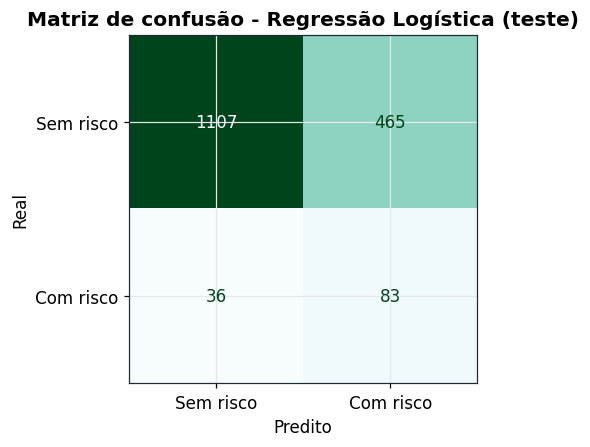

In [26]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score)

y_proba = clf.predict_proba(Xte_m)[:, 1]

print(classification_report(y_test, yp_log, target_names=["Sem risco", "Com risco"], digits=3))
print(f"AUC-ROC (teste): {roc_auc_score(y_test, y_proba):.3f}")

fig, ax = plt.subplots(figsize=(5, 4.2))
cm = confusion_matrix(y_test, yp_log)
ConfusionMatrixDisplay(cm, display_labels=["Sem risco", "Com risco"]).plot(
    ax=ax, cmap="BuGn", colorbar=False, values_format="d")
ax.set_title("Matriz de confusão - Regressão Logística (teste)")
ax.set_xlabel("Predito"); ax.set_ylabel("Real")
plt.show()

### 12.3 Curva ROC

A curva ROC mostra a capacidade discriminativa global do modelo em todos os limiares de decisão.

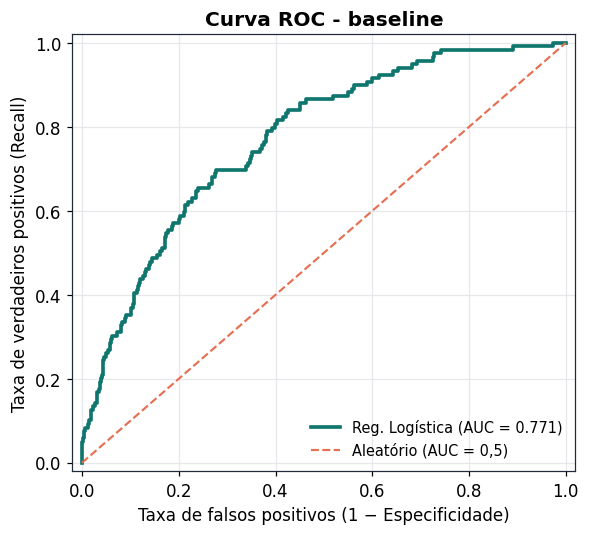

In [27]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color=TEAL, lw=2.4, label=f"Reg. Logística (AUC = {roc_auc:.3f})")
ax.plot([0, 1], [0, 1], color=CORAL, lw=1.4, ls="--", label="Aleatório (AUC = 0,5)")
ax.set_xlabel("Taxa de falsos positivos (1 − Especificidade)")
ax.set_ylabel("Taxa de verdadeiros positivos (Recall)")
ax.set_title("Curva ROC - baseline")
ax.legend(loc="lower right", frameon=False, fontsize=9.5)
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
plt.show()

### 12.4 Leitura dos coeficientes (interpretabilidade)

A Regressão Logística permite extrair a **razão de chances (odds ratio)** de cada preditor. Para as
variáveis numéricas escalonadas, a OR expressa a variação de chance por **1 desvio-padrão** de
aumento; para binárias/categóricas, por presença da condição. Prévia da explicabilidade que o SHAP
aprofundará no TCC.

In [28]:
nomes = clf.named_steps["pre"].get_feature_names_out()
coefs = clf.named_steps["logreg"].coef_[0]
imp = (pd.DataFrame({"atributo": nomes, "coef": coefs})
       .assign(odds_ratio=lambda d: np.exp(d["coef"]))
       .reindex(pd.Series(np.abs(coefs)).sort_values(ascending=False).index)
       .head(10).reset_index(drop=True))
imp["direcao"] = np.where(imp["coef"] > 0, "↑ risco", "↓ risco")
print("Top 10 atributos por magnitude do coeficiente:")
print(imp[["atributo", "coef", "odds_ratio", "direcao"]].to_string(
    index=False, float_format=lambda x: f"{x:7.3f}"))

Top 10 atributos por magnitude do coeficiente:
                atributo    coef  odds_ratio direcao
       nom__raca_cor_3.0   1.075       2.931 ↑ risco
     bin__colesterol_sim   0.648       1.912 ↑ risco
       nom__raca_cor_5.0   0.542       1.720 ↑ risco
              num__idade   0.407       1.502 ↑ risco
      bin__has_combinada   0.395       1.485 ↑ risco
              num__rcest   0.353       1.423 ↑ risco
nom__has_autorrelato_3.0  -0.342       0.711 ↓ risco
       nom__raca_cor_4.0   0.320       1.378 ↑ risco
       nom__raca_cor_2.0   0.302       1.353 ↑ risco
nom__has_autorrelato_2.0  -0.287       0.751 ↓ risco


## 13. Conclusão e aprendizado

Este notebook percorreu o pipeline completo de dados sobre a Subamostra Laboratorial da PNS 2013,
da base bruta ao modelo *baseline* de triagem de risco metabólico.

**Principais aprendizados técnicos:**

1. **O gargalo é entender os dados, não treinar o modelo.** A maior parte do esforço esteve na
   auditoria da base: a vírgula decimal que silenciosamente transformaria números em texto, os
   códigos de ausência disfarçados, e o mapeamento correto das variáveis contra o dicionário do
   IBGE. Modelar veio depois e foi a parte rápida.

2. **Prevenir *data leakage* condiciona a ordem do pipeline.** Imputação, escalonamento e
   codificação foram ajustados apenas no treino. Descobrimos que os ausentes contínuos coincidiam
   com um bloco de pessoas não medidas, removê-las esvaziou a necessidade de KNN e deslocou o
   tratamento real para a moda das categóricas.

3. **Acurácia engana em base desbalanceada.** Com ~7% de positivos, um classificador ingênuo
   alcança acurácia altíssima e Recall zero. Por isso o baseline prioriza **Recall** e usa
   `class_weight='balanced'`, aceitando queda de acurácia em troca de encontrar os casos de risco, exatamente o objetivo de uma ferramenta de triagem.

4. **Multicolinearidade é um trade-off consciente.** Variáveis antropométricas complementares
   inflam o VIF; mantê-las beneficia o desempenho preditivo, mas exige tratamento no plano da
   interpretabilidade, questão encaminhada para a fase seguinte do TCC.

**Limitações.** (i) Desenho transversal da PNS 2013 impede inferência causal e motivou a exclusão
de variáveis comportamentais (risco de causalidade reversa). (ii) A base não distingue DM1 de DM2;
o desfecho é hiperglicemia crônica (HbA1c ≥ 6,5%), majoritariamente DM2 na população adulta.
(iii) *Histórico familiar de diabetes*, preditor clássico, **não existe** na PNS 2013, ausência
registrada como limitação metodológica, não como omissão.


## 14. Referências da base utilizada

- INSTITUTO BRASILEIRO DE GEOGRAFIA E ESTATÍSTICA (IBGE). **Pesquisa Nacional de Saúde 2013:
  Exames Laboratoriais.** Rio de Janeiro: IBGE, 2013. Microdados. Disponível em:
  https://ftp.ibge.gov.br/PNS/2013/Divulgacoes/Outros/Exames/

- INSTITUTO BRASILEIRO DE GEOGRAFIA E ESTATÍSTICA (IBGE). **Nota Técnica: Exames Laboratoriais da
  Pesquisa Nacional de Saúde (PNS 2013).** Recálculo do peso amostral laboratorial (`Peso_Lab`).

- AMERICAN DIABETES ASSOCIATION. Diagnosis and classification of diabetes mellitus. **Diabetes
  Care**, v. 33, supl. 1, p. S62–S69, 2010. (Critério HbA1c ≥ 6,5%.)

- PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. **JMLR**, v. 12, p. 2825–2830, 2011.

*(Referencial teórico completo no Projeto de TCC I - Lorenzo de Ávila Carpes, IFFar São Borja, 2026.)*